## Imported important libraries

In [13]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load the Dataset

In [2]:
df = pd.read_csv('susceptibility_training_table.csv')

# See the first 5 rows

In [5]:
df.head(5)

,point_id,station_id,basin,lat,lon,elevation_m,slope_deg,dist_to_river_m,drainage_density_km_per_km2,landcover_class,label
0,SW90_0_0,SW90,brahmaputra,25.0997,89.5695,17.955149,0.611079,1010.434527,0.638643,40,0
1,SW90_0_1,SW90,brahmaputra,25.0997,89.5995,12.219988,4.605155,370.825399,0.814095,60,0
2,SW90_0_2,SW90,brahmaputra,25.0997,89.6295,17.696609,0.281487,263.586822,1.143943,30,0
3,SW90_0_3,SW90,brahmaputra,25.0997,89.6595,11.500000,0.000000,1445.847475,1.277286,80,0
4,SW90_0_4,SW90,brahmaputra,25.0997,89.6895,11.500000,0.000000,184.182700,1.228160,80,0


## See the Last 5 rows

In [6]:
df.tail(5)

,point_id,station_id,basin,lat,lon,elevation_m,slope_deg,dist_to_river_m,drainage_density_km_per_km2,landcover_class,label
1376,CO05_6_2,CO05,cht,21.5172,91.9758,5.616333,1.812375,632.809182,0.866229,95,0
1377,CO05_6_3,CO05,cht,21.5172,92.0058,0.000000,1.110126,1159.780050,0.664109,95,1
1378,CO05_6_4,CO05,cht,21.5172,92.0358,1.463102,0.226349,146.271124,1.335436,80,1
1379,CO05_6_5,CO05,cht,21.5172,92.0658,14.221318,6.446821,632.804099,1.097223,10,0
1380,CO05_6_6,CO05,cht,21.5172,92.0958,21.810600,8.129897,171.579168,1.775769,10,0


## Check The columns

In [7]:
df.columns

Index(['point_id', 'station_id', 'basin', 'lat', 'lon', 'elevation_m',
       'slope_deg', 'dist_to_river_m', 'drainage_density_km_per_km2',
       'landcover_class', 'label'],
      dtype='str')

## Dataset Shape

In [8]:
df.shape

(1381, 11)

There are almost 1381 rowns and 11 columns present in this dataset

## Dataset Information

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1381 entries, 0 to 1380
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   point_id                     1381 non-null   str    
 1   station_id                   1381 non-null   str    
 2   basin                        1381 non-null   str    
 3   lat                          1381 non-null   float64
 4   lon                          1381 non-null   float64
 5   elevation_m                  1381 non-null   float64
 6   slope_deg                    1381 non-null   float64
 7   dist_to_river_m              1381 non-null   float64
 8   drainage_density_km_per_km2  1381 non-null   float64
 9   landcover_class              1381 non-null   int64  
 10  label                        1381 non-null   int64  
dtypes: float64(6), int64(2), str(3)
memory usage: 144.6 KB


## Statistical Analysis

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
lat,1381.0,23.971219,1.183226,21.337200,22.875600,23.960000,24.925200,26.006700
lon,1381.0,90.475280,0.995364,88.939400,89.640900,90.299600,91.365000,92.308300
elevation_m,1381.0,17.587058,28.967232,-0.629735,4.463551,10.018256,18.898256,416.116669
slope_deg,1381.0,2.878753,4.460336,0.000000,0.289015,1.127268,3.813164,36.497028
dist_to_river_m,1381.0,723.299586,543.353662,0.001972,294.913080,618.622893,1052.860920,3131.194007
drainage_density_km_per_km2,1381.0,0.993578,0.406206,0.000000,0.715842,0.961474,1.256032,3.775313
landcover_class,1381.0,34.779146,22.749544,10.000000,10.000000,40.000000,40.000000,95.000000
label,1381.0,0.262129,0.439952,0.000000,0.000000,0.000000,1.000000,1.000000


## EDA

In [11]:
df.isna().sum()

point_id                       0
station_id                     0
basin                          0
lat                            0
lon                            0
elevation_m                    0
slope_deg                      0
dist_to_river_m                0
drainage_density_km_per_km2    0
landcover_class                0
label                          0
dtype: int64

There is no nan values present in this dataset

In [12]:
df.duplicated().sum()

np.int64(0)

There is no duplicated values present in this dataset

# Dataset Visualization

## Target Class Distribution

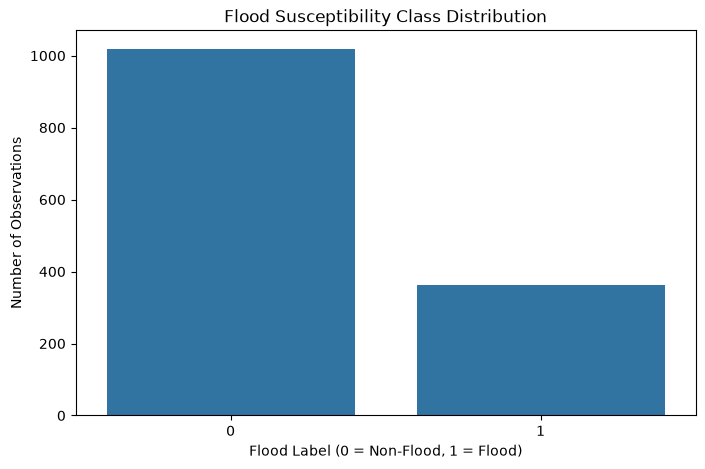

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="label")

plt.title("Flood Susceptibility Class Distribution")
plt.xlabel("Flood Label (0 = Non-Flood, 1 = Flood)")
plt.ylabel("Number of Observations")

plt.show()

## Correlation Heatmap

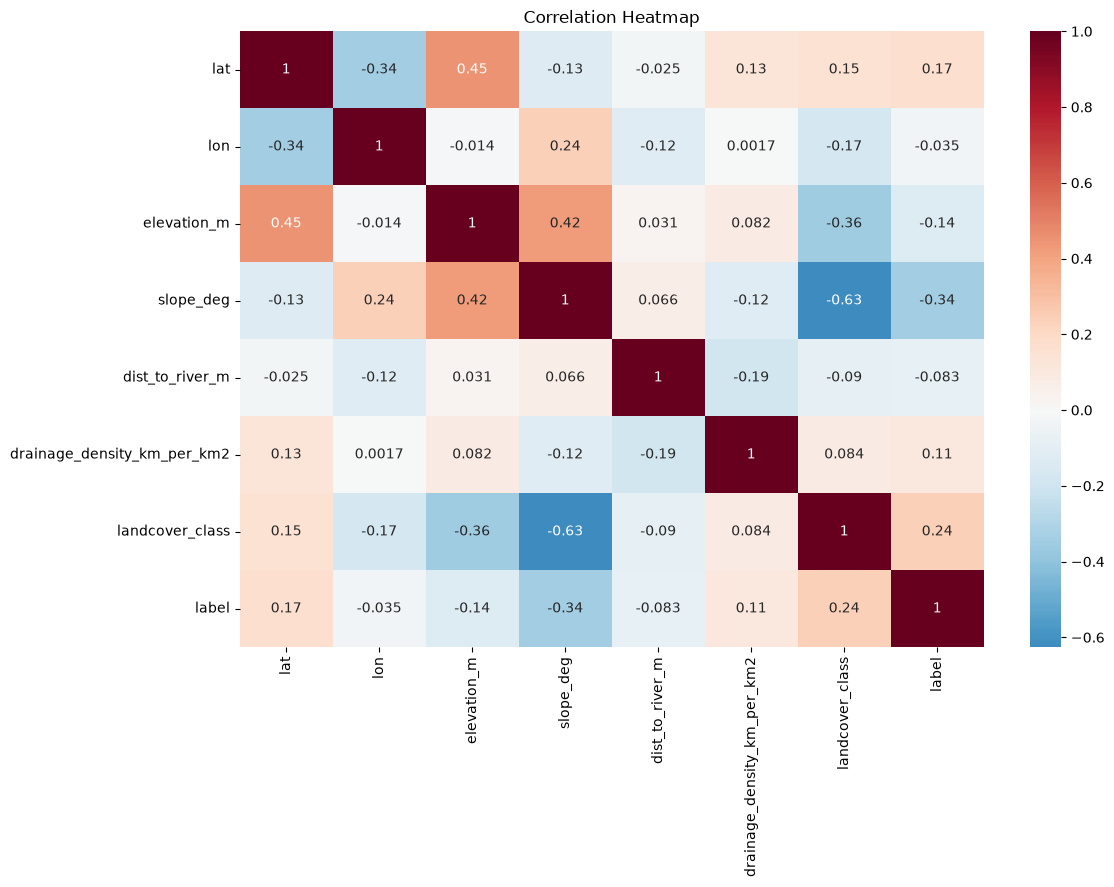

In [16]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.select_dtypes(include="number").corr(method="spearman"),annot=True, cmap="RdBu_r", center=0)
plt.title("Correlation Heatmap")
plt.show()

## Numerical Feature Distributions

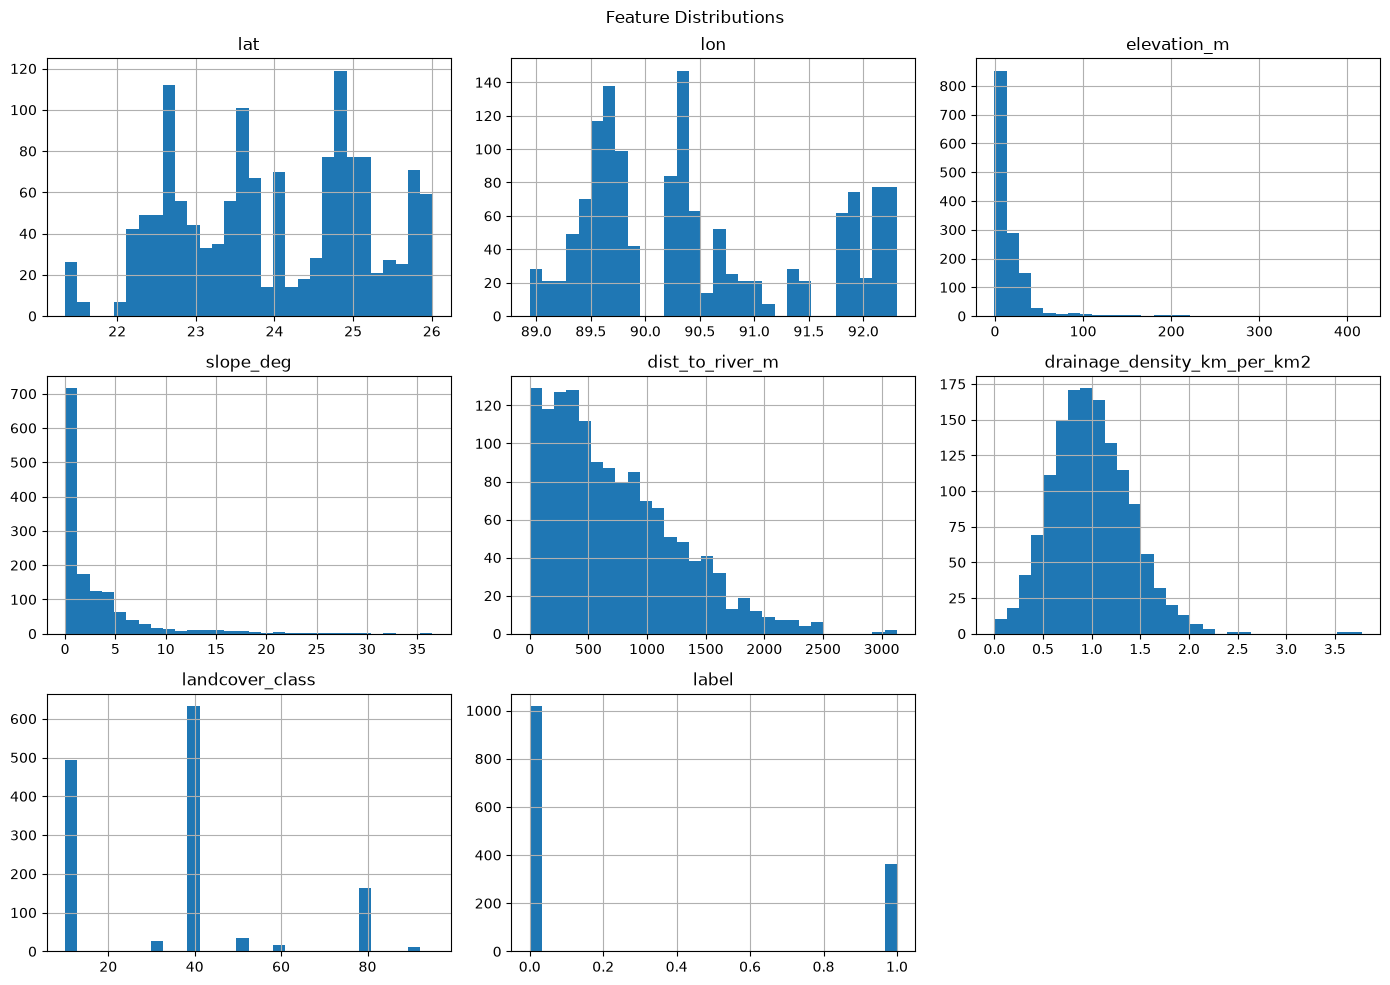

In [17]:
df.select_dtypes(include="number").hist(figsize=(14, 10), bins=30)
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

## Elevation vs Flood Label

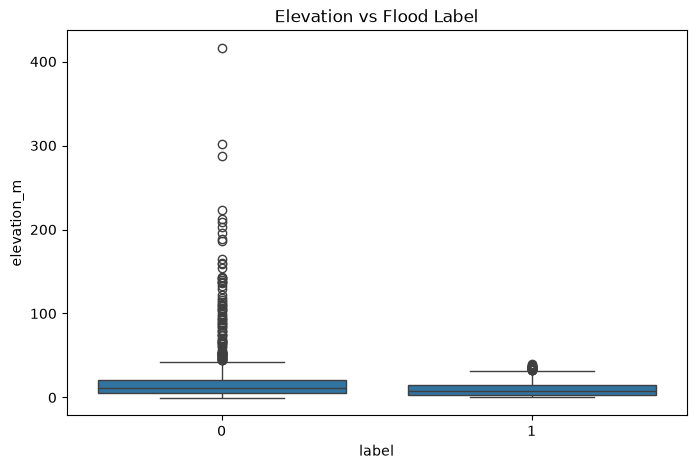

In [18]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="label", y="elevation_m")
plt.title("Elevation vs Flood Label")
plt.show()

## Distance to River vs Flood Label

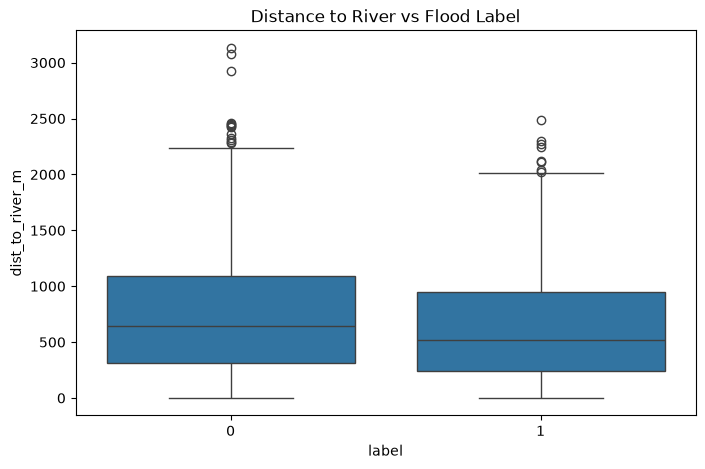

In [19]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="label", y="dist_to_river_m")
plt.title("Distance to River vs Flood Label")
plt.show()

## Geographic Flood Distribution